# Week 4, Part 2
## Feature Selection cont'd: Interactions, Outliers

Two datasets:

1. **Palmer penguins** 
2. **Bike rentals** 

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence

# Hello again Penguins 
peng = pd.read_csv("../data/penguins.csv").dropna(
    subset=["flipper_length_mm", "body_mass_g", "bill_length_mm", "bill_depth_mm"]
).reset_index(drop=True)

# and bikes!
bike = pd.read_csv("../data/bike-sharing-daily.csv", parse_dates=["dteday"])

## Interaction Terms

In [2]:
## Let's build on what we did last class and dig further into species as a predictor

additive    = smf.ols("body_mass_g ~ flipper_length_mm + C(species)", data=peng).fit()
interaction = smf.ols("body_mass_g ~ flipper_length_mm * C(species)", data=peng).fit()

print(additive.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.783
Model:                            OLS   Adj. R-squared:                  0.781
Method:                 Least Squares   F-statistic:                     405.7
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          1.25e-111
Time:                        19:15:50   Log-Likelihood:                -2510.8
No. Observations:                 342   AIC:                             5030.
Df Residuals:                     338   BIC:                             5045.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept               -4

In [3]:
print(interaction.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.790
Model:                            OLS   Adj. R-squared:                  0.786
Method:                 Least Squares   F-statistic:                     252.2
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          2.22e-111
Time:                        19:15:50   Log-Likelihood:                -2505.2
No. Observations:                 342   AIC:                             5022.
Df Residuals:                     336   BIC:                             5045.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

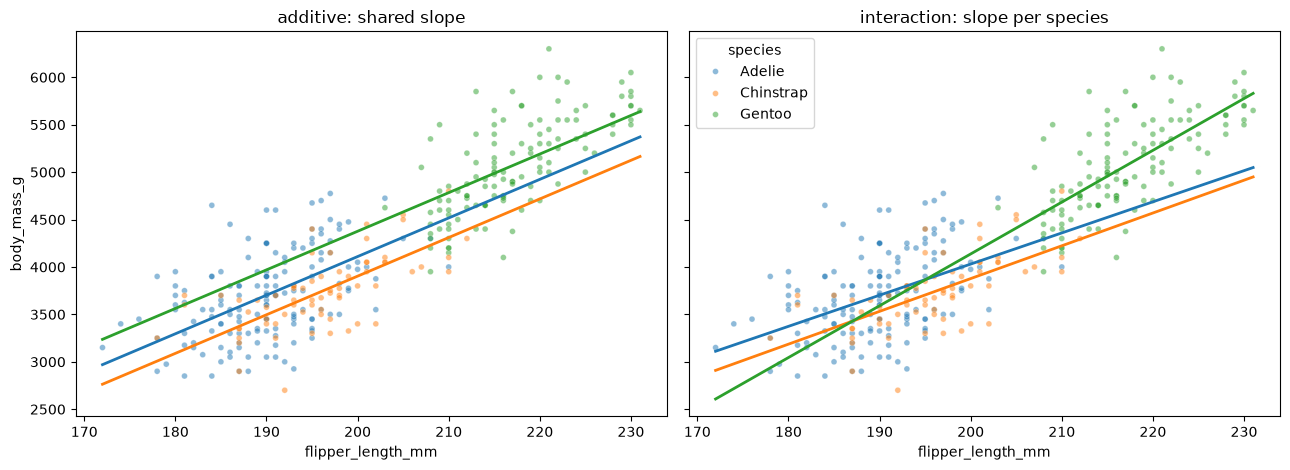

In [4]:
# Let's plot this 

species = sorted(peng.species.unique())
palette = dict(zip(species, sns.color_palette(n_colors=len(species))))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
grid = np.linspace(peng.flipper_length_mm.min(), peng.flipper_length_mm.max(), 50)

for ax, model, title in [(axes[0], additive, "additive: shared slope"),
                         (axes[1], interaction, "interaction: slope per species")]:
    sns.scatterplot(data=peng, x="flipper_length_mm", y="body_mass_g",
                    hue="species", hue_order=species, palette=palette,
                    alpha=0.5, s=18, ax=ax, legend=(ax is axes[1]))
    for sp in species:
        pred = model.predict(pd.DataFrame({"flipper_length_mm": grid, "species": sp}))
        ax.plot(grid, pred, lw=2, color=palette[sp])
    ax.set_title(title)
plt.tight_layout()

In [5]:
# Now let's use a nested F-test to see which model is truly better. 
compare = sm.stats.anova_lm(additive, interaction)
print(compare)

   df_resid           ssr  df_diff       ss_diff         F    Pr(>F)
0     338.0  4.766699e+07      0.0           NaN       NaN       NaN
1     336.0  4.614742e+07      2.0  1.519564e+06  5.531985  0.004327


In [6]:
# Let's now look at centering the data and see what that does to the model
# Note: Centering is a form of feature transformation!
# Note #2: This does not change the fit of the model!

peng["flipper_c"] = peng.flipper_length_mm - peng.flipper_length_mm.mean()
peng["bill_len_c"] = peng.bill_length_mm - peng.bill_length_mm.mean()

add_ctr    = smf.ols("body_mass_g ~ flipper_c + C(species)", data=peng).fit()
interact_ctr = smf.ols("body_mass_g ~ flipper_c * C(species)", data=peng).fit()

In [7]:
# Let's compare centered and non-centered data 

print(pd.DataFrame({"raw": interaction.params, "centered": interact_ctr.params.values}).round(3))
print(f"\nR^2: raw {interaction.rsquared:.6f}   centered {interact_ctr.rsquared:.6f}   (identical model)")

                                                raw  centered
Intercept                                 -2535.837  4060.549
C(species)[T.Chinstrap]                    -501.359  -151.424
C(species)[T.Gentoo]                      -4251.444   126.662
flipper_length_mm                            32.832    32.832
flipper_length_mm:C(species)[T.Chinstrap]     1.742     1.742
flipper_length_mm:C(species)[T.Gentoo]       21.791    21.791

R^2: raw 0.789577   centered 0.789577   (identical model)


In [8]:
# Let's look at VIF and multicollinearity

def vif_table(model):
    # skip the intercept column (index 0)
    X = model.model.exog
    return [variance_inflation_factor(X, i) for i in range(1, X.shape[1])]

print(pd.DataFrame({"raw": vif_table(interaction), "centered": vif_table(interact_ctr)},
                   index=interact_ctr.model.exog_names[1:]).round(2))

                                       raw  centered
C(species)[T.Chinstrap]             920.63      2.60
C(species)[T.Gentoo]               1168.33      6.70
flipper_c                            10.51     10.51
flipper_c:C(species)[T.Chinstrap]   940.23      2.17
flipper_c:C(species)[T.Gentoo]     1305.11      9.12


In [9]:
print(interact_ctr.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.790
Model:                            OLS   Adj. R-squared:                  0.786
Method:                 Least Squares   F-statistic:                     252.2
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          2.22e-111
Time:                        19:15:50   Log-Likelihood:                -2505.2
No. Observations:                 342   AIC:                             5022.
Df Residuals:                     336   BIC:                             5045.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

In [10]:
compare_ctr = sm.stats.anova_lm(add_ctr, interact_ctr)
print(compare_ctr)

   df_resid           ssr  df_diff       ss_diff         F    Pr(>F)
0     338.0  4.766699e+07      0.0           NaN       NaN       NaN
1     336.0  4.614742e+07      2.0  1.519564e+06  5.531985  0.004327


In [11]:
# Now let's look at the bike data
bike_additive = smf.ols("cnt ~ temp + C(workingday) + hum + windspeed", data=bike).fit()
bike_int = smf.ols("cnt ~ temp * C(workingday) + hum + windspeed", data=bike).fit()

In [12]:
bike_compare = sm.stats.anova_lm(bike_additive, bike_int)
print(bike_compare)

   df_resid           ssr  df_diff       ss_diff         F    Pr(>F)
0     726.0  1.474404e+09      0.0           NaN       NaN       NaN
1     725.0  1.469570e+09      1.0  4.834195e+06  2.384909  0.122948


In [13]:
print(bike_int.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.464
Model:                            OLS   Adj. R-squared:                  0.460
Method:                 Least Squares   F-statistic:                     125.3
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           1.47e-95
Time:                        19:15:50   Log-Likelihood:                -6342.0
No. Observations:                 731   AIC:                         1.270e+04
Df Residuals:                     725   BIC:                         1.272e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                3

## Outliers and High Leverage Values

In [14]:
# Three different things. Fit a working model on the bike data first.

model = smf.ols("cnt ~ temp + hum + windspeed + C(season) + C(weathersit)", data=bike).fit()
infl = OLSInfluence(model) # Class that calculates outlier and influence measures for an OLS result

n, p = int(model.nobs), model.df_model
print(f"n = {n}, p = {p:.0f} ")
print("----------------------")
print(model.summary())


n = 731, p = 8 
----------------------
                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.556
Model:                            OLS   Adj. R-squared:                  0.551
Method:                 Least Squares   F-statistic:                     113.2
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          5.27e-122
Time:                        19:15:50   Log-Likelihood:                -6272.6
No. Observations:                 731   AIC:                         1.256e+04
Df Residuals:                     722   BIC:                         1.260e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------

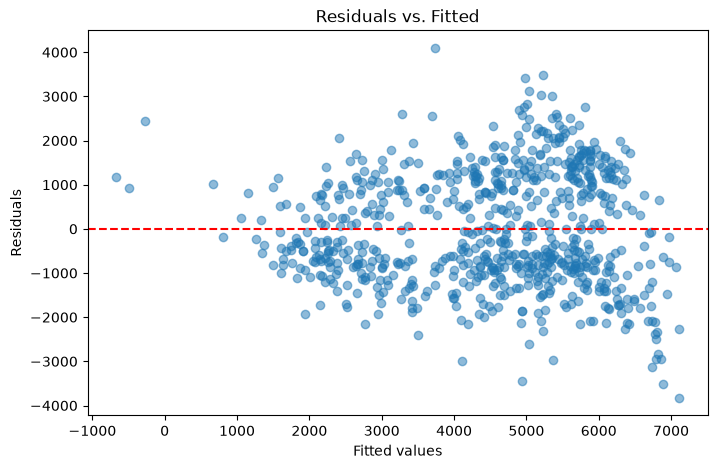

In [15]:
# Let's plot fitted vs residuals
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(model.fittedvalues, model.resid, alpha=0.5)
ax.axhline(0, color="red", linestyle="--")
ax.set_xlabel("Fitted values")
ax.set_ylabel("Residuals")
ax.set_title("Residuals vs. Fitted")
plt.show()

In [16]:
bike.cnt

0       985
1       801
2      1349
3      1562
4      1600
       ... 
726    2114
727    3095
728    1341
729    1796
730    2729
Name: cnt, Length: 731, dtype: int64

In [17]:
# Now let's build a dataframe calculating metrics for residuals, leverage, and cooks_d
diag = pd.DataFrame({
    "date":      bike.dteday,
    "cnt":       bike.cnt,
    "fitted":    model.fittedvalues,
    "residuals": model.resid,
    "student_resid": infl.resid_studentized_external,
    "leverage":  infl.hat_matrix_diag,
    "cooks_d":   infl.cooks_distance[0],
})

diag.head(10)

,date,cnt,fitted,residuals,student_resid,leverage,cooks_d
0,2011-01-01,985,2387.948181,-1402.948181,-1.086938,0.010072,0.001335
1,2011-01-02,801,2503.560803,-1702.560803,-1.319008,0.009224,0.001798
2,2011-01-03,1349,2368.102043,-1019.102043,-0.788576,0.008389,0.000585
3,2011-01-04,1562,2280.209969,-718.209969,-0.555898,0.009356,0.000325
4,2011-01-05,1600,2763.317015,-1163.317015,-0.900206,0.008212,0.000746
5,2011-01-06,1606,2732.970861,-1126.970861,-0.873764,0.012094,0.001039
6,2011-01-07,1510,2253.529586,-743.529586,-0.576795,0.013784,0.000517
7,2011-01-08,959,1633.383671,-674.383671,-0.522633,0.011896,0.000366
8,2011-01-09,822,1637.667040,-815.667040,-0.633113,0.014803,0.000670
9,2011-01-10,1321,2048.693737,-727.693737,-0.563282,0.009498,0.000338


In [18]:
# Now let's look at the cutoff values for this data, based on the formulas we looked at in the slides

lev_cut, cook_cut = 2 * (p + 1) / n, 4 / n
print(f"n = {n}, p = {p:.0f}   leverage cutoff = {lev_cut:.4f}   Cook's D cutoff = {cook_cut:.4f}")

# Count of observations that get flagged by each diagnostic
print(f"\noutliers   (|studentized resid| > 3): {(diag.student_resid.abs() > 3).sum()}")
print(f"high leverage (h > 2(p+1)/n):        {(diag.leverage > lev_cut).sum()}")
print(f"influential   (Cook's D > 4/n):      {(diag.cooks_d > cook_cut).sum()}")

n = 731, p = 8   leverage cutoff = 0.0246   Cook's D cutoff = 0.0055

outliers   (|studentized resid| > 3): 1
high leverage (h > 2(p+1)/n):        27
influential   (Cook's D > 4/n):      24


In [19]:
# Which point is the outlier
diag[diag.student_resid.abs() > 3]


,date,cnt,fitted,residuals,student_resid,leverage,cooks_d
441,2012-03-17,7836,3740.305424,4095.694576,3.203567,0.016568,0.018968


In [20]:
# Which are points of high leverage
diag[diag.leverage > lev_cut]

,date,cnt,fitted,residuals,student_resid,leverage,cooks_d
25,2011-01-26,506,-675.822941,1181.822941,0.936482,0.054084,0.005572
49,2011-02-19,1635,3420.484803,-1785.484803,-1.402511,0.035946,0.008138
64,2011-03-06,605,1604.398035,-999.398035,-0.780146,0.025662,0.001782
68,2011-03-10,623,2768.295732,-2145.295732,-1.786398,0.140681,0.057873
89,2011-03-31,1685,673.273684,1011.726316,0.805414,0.063092,0.004856
105,2011-04-16,795,1350.480644,-555.480644,-0.440546,0.056612,0.001296
159,2011-06-09,3915,6856.288848,-2941.288848,-2.302274,0.024649,0.014796
248,2011-09-06,2710,1565.439485,1144.560515,0.909250,0.058920,0.005753
249,2011-09-07,1996,2675.652901,-679.652901,-0.539485,0.058092,0.001996
250,2011-09-08,1842,2513.175163,-671.175163,-0.531571,0.053898,0.001790


In [21]:
# Which are points that are influential
diag[diag.cooks_d > cook_cut]

,date,cnt,fitted,residuals,student_resid,leverage,cooks_d
25,2011-01-26,506,-675.822941,1181.822941,0.936482,0.054084,0.005572
49,2011-02-19,1635,3420.484803,-1785.484803,-1.402511,0.035946,0.008138
68,2011-03-10,623,2768.295732,-2145.295732,-1.786398,0.140681,0.057873
86,2011-03-28,2028,4193.204095,-2165.204095,-1.689834,0.022211,0.007189
150,2011-05-31,3982,6816.554779,-2834.554779,-2.206841,0.014697,0.008029
159,2011-06-09,3915,6856.288848,-2941.288848,-2.302274,0.024649,0.014796
202,2011-07-22,3387,6891.678754,-3504.678754,-2.725279,0.008840,0.007295
203,2011-07-23,3285,7115.024855,-3830.024855,-2.984164,0.010746,0.010632
238,2011-08-27,1115,4110.168469,-2995.168469,-2.344279,0.024247,0.015080
248,2011-09-06,2710,1565.439485,1144.560515,0.909250,0.058920,0.005753


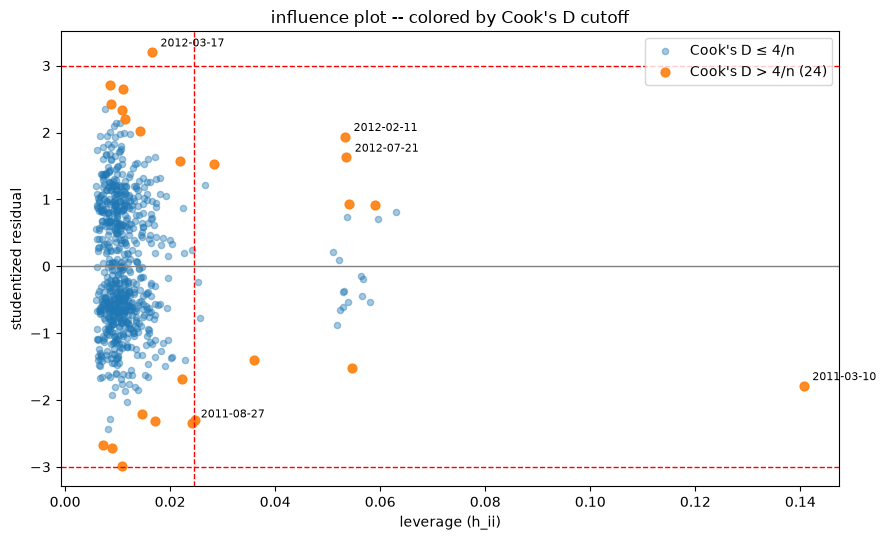

In [22]:
# Plot all three at once: studentized residual vs. leverage, colored by Cook's D cutoff.
infl = diag.cooks_d > cook_cut

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(diag.leverage[~infl], diag.student_resid[~infl], s=20, alpha=0.4,
           color="tab:blue", label=f"Cook's D ≤ 4/n")
ax.scatter(diag.leverage[infl], diag.student_resid[infl], s=40, alpha=0.9,
           color="tab:orange", label=f"Cook's D > 4/n ({infl.sum()})")
ax.axhline(0, color="gray", lw=1)
for y in (-3, 3):
    ax.axhline(y, color="red", ls="--", lw=1)
ax.axvline(lev_cut, color="red", ls="--", lw=1)
ax.set(xlabel="leverage (h_ii)", ylabel="studentized residual",
       title="influence plot -- colored by Cook's D cutoff")
ax.legend()

for _, r in diag.nlargest(5, "cooks_d").iterrows():
    ax.annotate(r.date.strftime("%Y-%m-%d"), (r.leverage, r.student_resid),
                fontsize=8, xytext=(6, 4), textcoords="offset points")
plt.tight_layout()

In [23]:
# Impact of removing influential points
keep = diag.cooks_d <= cook_cut
trimmed = smf.ols("cnt ~ temp + hum + windspeed + C(season) + C(weathersit)",
                  data=bike[keep.values]).fit()

print(pd.DataFrame({
    "all data": model.params,
    "influential dropped": trimmed.params,
    "% change": 100 * (trimmed.params - model.params) / model.params.abs(),
}).round(2))
print(f"\ndropped {(~keep).sum()} of {n} observations")
print(f"R^2: {model.rsquared:.4f} -> {trimmed.rsquared:.4f}")

                    all data  influential dropped  % change
Intercept            3128.94              3343.39      6.85
C(season)[T.2]        926.97               968.00      4.43
C(season)[T.3]        471.32               422.60    -10.34
C(season)[T.4]       1496.78              1591.51      6.33
C(weathersit)[T.2]   -218.77              -147.80     32.44
C(weathersit)[T.3]  -1902.85             -1913.65     -0.57
temp                 6205.41              6491.29      4.61
hum                 -2635.17             -3212.84    -21.92
windspeed           -3330.79             -3555.34     -6.74

dropped 24 of 731 observations
R^2: 0.5564 -> 0.5971
